# What sells on Tokopedia

Product data from PRDECT-ID, a set of 5,400 Tokopedia reviews across 29 categories published in *Data in Brief* (2022). Each review row carries its product's price, seller location, overall rating, units sold and review count. Collapsed to one row per product, that gives 1,308 products.

Questions:

1. Where are the sellers?
2. How do price and units sold differ between categories?
3. Within a category, how does price relate to units sold?
4. Does the overall star rating tell products apart?
5. How many buyers leave a review, and does it depend on the category?

The reviews themselves were selected by the dataset authors, and their sentiment and emotion labels are close to evenly split within categories, so they are not used to measure satisfaction here.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import chart_style as cs

cs.apply()
IMAGES = ROOT / "images"
RESULTS = ROOT / "results"
SOURCE = "Source: PRDECT-ID (Sutoyo et al., 2022), Tokopedia product reviews, 1,308 products."
GREATER_JAKARTA = "Jakarta|Tangerang|Bekasi|Depok|Bogor"

In [2]:
reviews = pd.read_csv(ROOT / "data/raw/prdect_id.csv")
print(f"{len(reviews):,} review rows, {reviews['Product Name'].nunique():,} products, {reviews['Category'].nunique()} categories")
reviews.head(3)

5,400 review rows, 1,308 products, 29 categories


,Category,Product Name,Location,Price,Overall Rating,Number Sold,Total Review,Customer Rating,Customer Review,Sentiment,Emotion
0,Computers and Laptops,Wireless Keyboard i8 Mini TouchPad Mouse 2.4G ...,Jakarta Utara,53500,4.9,5449,2369,5,Alhamdulillah berfungsi dengan baik. Packaging...,Positive,Happy
1,Computers and Laptops,PAKET LISENSI WINDOWS 10 PRO DAN OFFICE 2019 O...,Kota Tangerang Selatan,72000,4.9,2359,1044,5,"barang bagus dan respon cepat, harga bersaing ...",Positive,Happy
2,Computers and Laptops,SSD Midasforce 128 Gb - Tanpa Caddy,Jakarta Barat,213000,5.0,12300,3573,5,"barang bagus, berfungsi dengan baik, seler ram...",Positive,Happy


## One row per product

A product appears once per sampled review. For 39 products the units sold or review count differ slightly between rows (they were read at different times), so the highest value is kept. Price and rating use the median.

In [3]:
products = (
    reviews.groupby("Product Name")
    .agg(category=("Category", "first"),
         location=("Location", "first"),
         price=("Price", "median"),
         rating=("Overall Rating", "median"),
         units_sold=("Number Sold", "max"),
         review_count=("Total Review", "max"))
    .reset_index()
    .rename(columns={"Product Name": "product"})
)
products["greater_jakarta"] = products["location"].str.contains(GREATER_JAKARTA)
products["reviews_per_unit"] = products["review_count"] / products["units_sold"]
products.describe().round(2)

,price,rating,units_sold,review_count,reviews_per_unit
count,1308.00,1308.00,1308.00,1308.00,1308.00
mean,271264.26,4.86,9522.86,1705.49,0.38
std,913144.26,0.11,40794.14,2339.83,0.23
min,100.00,4.10,9.00,4.00,0.00
25%,25000.00,4.80,1235.75,453.75,0.24
50%,65000.00,4.90,3014.00,994.00,0.39
75%,150000.00,4.90,7493.50,2099.00,0.52
max,15399000.00,5.00,1000000.00,24500.00,3.33


## 1. Where the sellers are

In [4]:
by_city = (
    products.groupby("location")
    .agg(products=("product", "size"), units_sold=("units_sold", "sum"))
    .sort_values("units_sold", ascending=False)
)
by_city["share_of_units"] = by_city["units_sold"] / by_city["units_sold"].sum()
by_city.to_csv(RESULTS / "sellers_by_city.csv")

jkt = products.groupby("greater_jakarta").agg(products=("product", "size"), units=("units_sold", "sum"))
print(f"Greater Jakarta sellers: {jkt.loc[True, 'products'] / jkt['products'].sum():.0%} of products, "
      f"{jkt.loc[True, 'units'] / jkt['units'].sum():.0%} of units sold")
by_city.head(10)

Greater Jakarta sellers: 87% of products, 92% of units sold


,products,units_sold,share_of_units
location,,,
Jakarta Barat,331,3203804,0.257212
Jakarta Utara,205,2238987,0.179753
Kota Tangerang,90,1650336,0.132494
Jakarta Timur,75,1278767,0.102664
Jakarta Pusat,126,751417,0.060326
Kab. Tangerang,69,577412,0.046357
Jakarta Selatan,71,527787,0.042372
Kota Bandung,43,451044,0.036211
Kota Bekasi,45,445607,0.035775


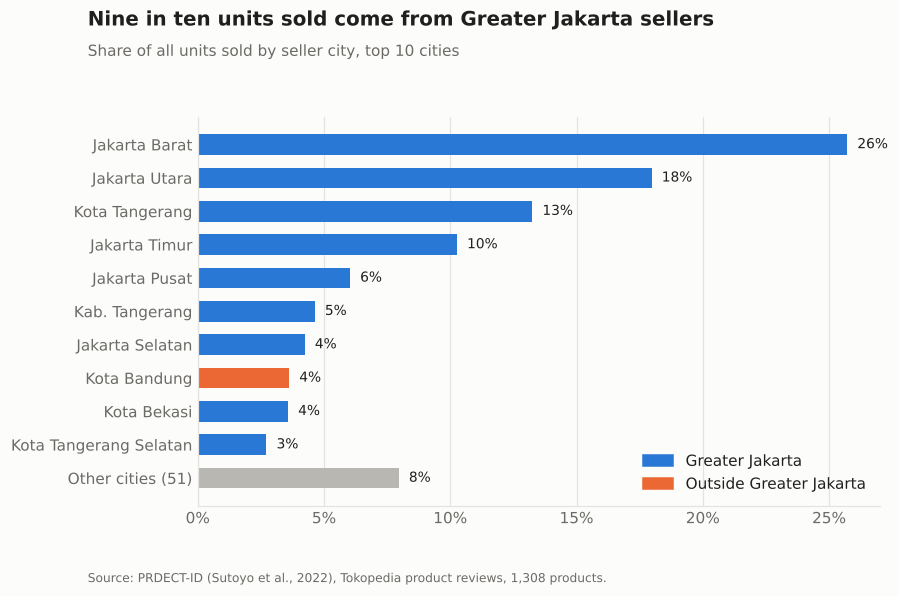

In [5]:
top = by_city.head(10)["share_of_units"]
rest = 1 - top.sum()
plot = pd.concat([top, pd.Series({"Other cities (51)": rest})])[::-1]
colors = [cs.NEUTRAL if name.startswith("Other") else
          (cs.SERIES[0] if pd.Series([name]).str.contains(GREATER_JAKARTA).iloc[0] else cs.SERIES[1])
          for name in plot.index]

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(plot.index, plot * 100, color=colors, height=0.62)
for y, v in enumerate(plot * 100):
    ax.text(v + 0.4, y, f"{v:.0f}%", va="center", fontsize=9, color=cs.INK)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (cs.SERIES[0], cs.SERIES[1])]
ax.legend(handles, ["Greater Jakarta", "Outside Greater Jakarta"], loc="lower right")
cs.titles(fig, "Nine in ten units sold come from Greater Jakarta sellers",
          "Share of all units sold by seller city, top 10 cities", SOURCE)
cs.save(fig, IMAGES / "01_seller_cities.png")
fig

## 2. Categories: price against units sold

Median price and median units sold per category, both on a log scale because they span several orders of magnitude.

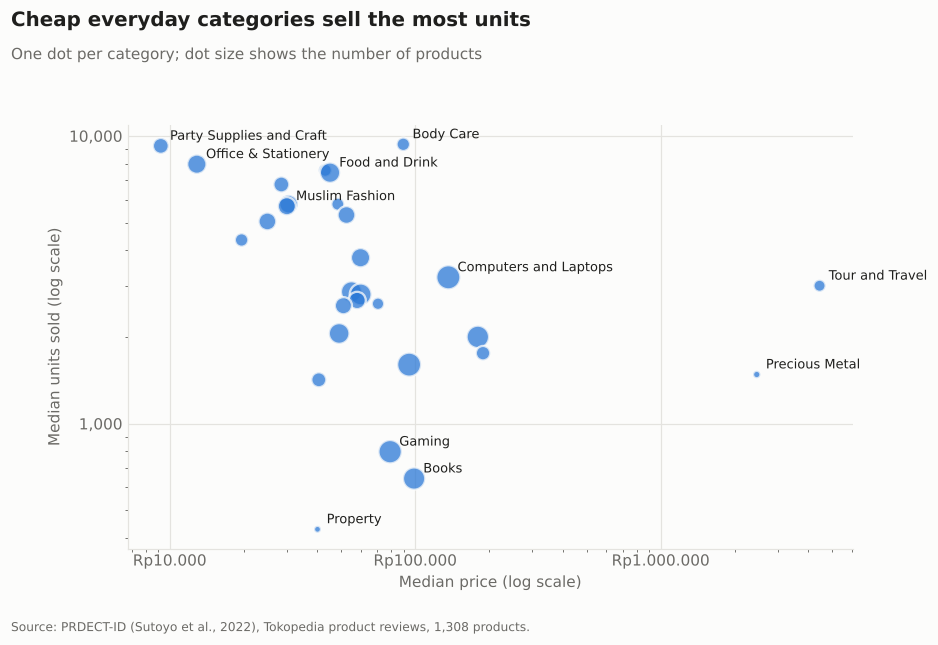

In [6]:
by_category = (
    products.groupby("category")
    .agg(products=("product", "size"), median_price=("price", "median"),
         median_units=("units_sold", "median"), median_reviews_per_unit=("reviews_per_unit", "median"))
    .sort_values("median_units", ascending=False)
)
by_category.round(3).to_csv(RESULTS / "categories.csv")

label = {"Party Supplies and Craft", "Office & Stationery", "Body Care", "Food and Drink", "Books",
         "Gaming", "Property", "Tour and Travel", "Precious Metal", "Computers and Laptops", "Muslim Fashion"}
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(by_category["median_price"], by_category["median_units"], s=by_category["products"] * 3,
           color=cs.SERIES[0], alpha=0.75, edgecolor=cs.SURFACE, linewidth=1.5)
for name, row in by_category.iterrows():
    if name in label:
        ax.annotate(name, (row["median_price"], row["median_units"]), xytext=(6, 4),
                    textcoords="offset points", fontsize=8.5, color=cs.INK)
ax.set_xscale("log")
ax.set_yscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"Rp{v:,.0f}".replace(",", ".")))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_xlabel("Median price (log scale)")
ax.set_ylabel("Median units sold (log scale)")
ax.grid(axis="x", visible=True)
cs.titles(fig, "Cheap everyday categories sell the most units",
          "One dot per category; dot size shows the number of products", SOURCE)
cs.save(fig, IMAGES / "02_categories.png")
fig

## 3. Price within a category

Comparing a phone with a pack of balloons says nothing about pricing. To compare like with like, each product's price is expressed against its category's median, and products are grouped into five price bands. The chart shows the median units sold per band, also relative to the category median.

In [7]:
products["price_vs_category"] = products["price"] / products.groupby("category")["price"].transform("median")
products["units_vs_category"] = products["units_sold"] / products.groupby("category")["units_sold"].transform("median")
products["price_band"] = pd.qcut(products["price_vs_category"], 5,
                                 labels=["Cheapest 20%", "2nd", "Middle", "4th", "Priciest 20%"])
bands = products.groupby("price_band", observed=True).agg(
    products=("product", "size"),
    price_vs_category=("price_vs_category", "median"),
    units_vs_category=("units_vs_category", "median"),
)
bands.round(2).to_csv(RESULTS / "price_bands.csv")
bands.round(2)

,products,price_vs_category,units_vs_category
price_band,,,
Cheapest 20%,263,0.22,1.66
2nd,260,0.61,1.24
Middle,262,1.00,1.00
4th,261,1.97,0.78
Priciest 20%,262,5.43,0.65


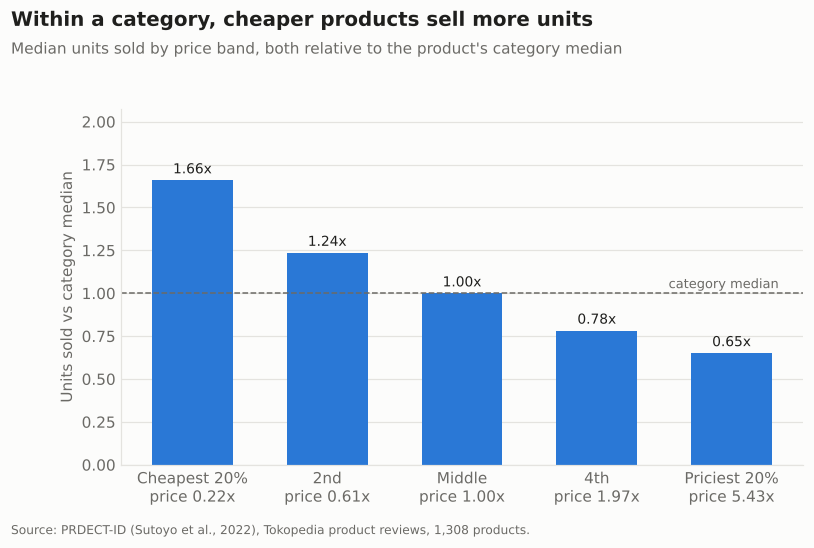

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
tick_labels = [f"{band}\nprice {pr:.2f}x" for band, pr in zip(bands.index.astype(str), bands["price_vs_category"])]
ax.bar(tick_labels, bands["units_vs_category"], color=cs.SERIES[0], width=0.6)
ax.axhline(1, color=cs.MUTED, lw=1, ls="--")
ax.text(4.35, 1.03, "category median", fontsize=8.5, color=cs.MUTED, ha="right")
for x, v in enumerate(bands["units_vs_category"]):
    ax.text(x, v + 0.04, f"{v:.2f}x", ha="center", fontsize=9, color=cs.INK)
ax.set_ylim(0, max(bands["units_vs_category"]) * 1.25)
ax.set_ylabel("Units sold vs category median")
cs.titles(fig, "Within a category, cheaper products sell more units",
          "Median units sold by price band, both relative to the product's category median", SOURCE)
cs.save(fig, IMAGES / "03_price_bands.png")
fig

The same relationship as a regression: log units sold on log price and the overall rating, with a fixed effect for each category and robust standard errors. This is an association across products, not a price elasticity from price changes on the same product.

In [9]:
products["log_units"] = np.log(products["units_sold"])
products["log_price"] = np.log(products["price"])
model = smf.ols("log_units ~ log_price + rating + greater_jakarta + C(category)", data=products).fit(cov_type="HC3")
summary = model.summary2().tables[1].loc[["log_price", "rating", "greater_jakarta[T.True]"],
                                        ["Coef.", "Std.Err.", "P>|z|"]]
summary.round(3).to_csv(RESULTS / "regression.csv")
print(f"R-squared {model.rsquared:.2f}, n = {int(model.nobs)}")
summary.round(3)

R-squared 0.39, n = 1308


,Coef.,Std.Err.,P>|z|
log_price,-0.407,0.029,0.000
rating,1.491,0.366,0.000
greater_jakarta[T.True],0.161,0.096,0.092


In [10]:
b_price = model.params["log_price"]
b_rating = model.params["rating"]
print(f"10% higher price: {np.exp(b_price * np.log(1.1)) - 1:+.1%} units sold")
print(f"0.1 higher rating: {np.exp(b_rating * 0.1) - 1:+.1%} units sold")

10% higher price: -3.8% units sold
0.1 higher rating: +16.1% units sold


## 4. Overall ratings barely separate products

87% of products have an overall rating of 4.8 or higher


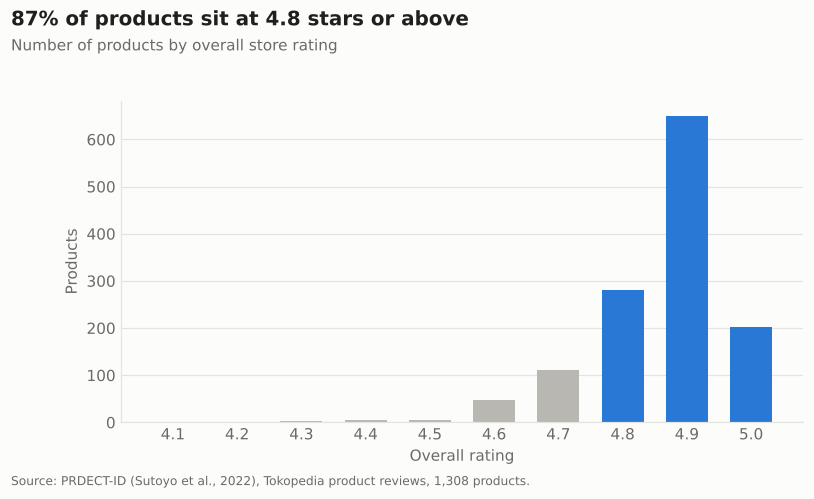

In [11]:
share_high = (products["rating"] >= 4.8).mean()
print(f"{share_high:.0%} of products have an overall rating of 4.8 or higher")
counts = products["rating"].round(1).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(counts.index.astype(str), counts.values,
       color=[cs.SERIES[0] if r >= 4.8 else cs.NEUTRAL for r in counts.index], width=0.65)
ax.set_xlabel("Overall rating")
ax.set_ylabel("Products")
cs.titles(fig, f"{share_high:.0%} of products sit at 4.8 stars or above",
          "Number of products by overall store rating", SOURCE)
cs.save(fig, IMAGES / "04_ratings.png")
fig

## 5. How many buyers leave a review

Reviews per unit sold is the review count divided by units sold. It differs a lot between categories, which matters when review counts are used as a stand-in for sales.

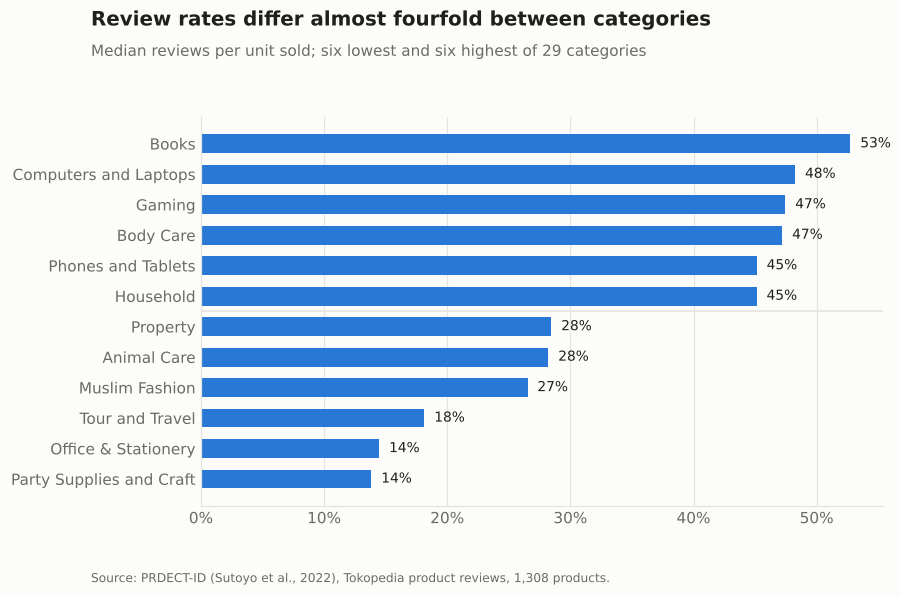

In [12]:
rate = by_category["median_reviews_per_unit"].sort_values()
show = pd.concat([rate.head(6), rate.tail(6)])

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(show.index, show * 100, color=cs.SERIES[0], height=0.62)
ax.axhline(5.5, color=cs.GRID, lw=1)
for y, v in enumerate(show * 100):
    ax.text(v + 0.8, y, f"{v:.0f}%", va="center", fontsize=9, color=cs.INK)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
cs.titles(fig, "Review rates differ almost fourfold between categories",
          "Median reviews per unit sold; six lowest and six highest of 29 categories", SOURCE)
cs.save(fig, IMAGES / "05_review_rate.png")
fig

## Summary

- Sellers in Greater Jakarta account for 87% of products and 92% of units sold in this sample; Jakarta Barat alone has a quarter of the products. Holding price, rating and category fixed, Greater Jakarta sellers sell about 17% more units, but the difference is not statistically clear (p = 0.09).
- Low-price, frequently bought categories (party supplies, stationery, body care, food) have the highest median units sold. Books, gaming and property sell the fewest.
- Within a category, the cheapest fifth of products sells 1.7 times the category median, the priciest fifth about two thirds of it. In the regression, 10% higher price goes with about 4% fewer units sold.
- 87% of products are rated 4.8 or higher, so the overall rating hardly separates products. A 0.1 point higher rating still goes with about 16% more units sold.
- Reviews per unit sold range from 14% for party supplies and stationery to 53% for books. Ranking products by review count understates sales of cheap bulk items.

Limits: PRDECT-ID is a curated sample (up to 200 reviews per category), not a census of Tokopedia. Units sold is Tokopedia's own counter, which caps display values and mixes product variants.